# Debug Automatic Gating
This notebook debugs the `GatingManager` and its strategies (Density, GMM) using test data from `/home/shared/Glow/debug_processed`.

In [ ]:
import sys
import os
import matplotlib.pyplot as plt
import numpy as np

# Add parent dir
sys.path.append(os.path.abspath(".."))

from glow.data_loading.loader import DataLoader
from glow.gating.manager import GatingManager
from glow.gating.strategies import OutlierDetector

In [2]:
# 1. Load Data
DEBUG_DIR = "/home/shared/Glow/debug_processed"
loader = DataLoader()

# List files
files = glob.glob(os.path.join(DEBUG_DIR, "*.fcs"))
print(f"Found {len(files)} files.")
files.sort()

# Load the first file for testing
target_file = files[0]
print(f"Loading: {target_file}")

# Manually prepare metadata for loading
# We use a dummy condition to make it a valid experiment, though usually not strictly needed for raw gating test
metadata = [{'original_path': target_file, 'display_name': os.path.basename(target_file), 'current_path': target_file, 'Timepoint': '0h'}]

experiment = loader.load_as_cytoflow_experiment(metadata)
print(f"Experiment loaded. Events: {len(experiment.data)}")
print(f"Channels: {experiment.channels}")

Found 10 files.
Loading: /home/shared/Glow/debug_processed/dhy_20251001_fcs_A1.fcs
Experiment loaded. Events: 19184
Channels: ['Event Info', 'FSC 488/10-A', 'FSC 488/10-H', 'FSC 488/10-W', 'GFP-A', 'GFP-H', 'GFP-W', 'SSC 488/10-A', 'SSC 488/10-H', 'SSC 488/10-W', 'TIME', 'TLSW', 'TMSW', 'TagBFP-A', 'TagBFP-H', 'TagBFP-W', 'mCherry-A', 'mCherry-H', 'mCherry-W']


/home/dhy/miniconda3/envs/glow_env/lib/python3.12/site-packages/cytoflow/operations/import_op.py:420: CytoflowOpWarning: The data range $PnR doesn't match the data bits $PnB for channel TLSW, masking out 1 bits
/home/dhy/miniconda3/envs/glow_env/lib/python3.12/site-packages/cytoflow/operations/import_op.py:420: CytoflowOpWarning: The data range $PnR doesn't match the data bits $PnB for channel TMSW, masking out 1 bits
/home/dhy/miniconda3/envs/glow_env/lib/python3.12/site-packages/cytoflow/operations/import_op.py:420: CytoflowOpWarning: The data range $PnR doesn't match the data bits $PnB for channel Event Info, masking out 1 bits
/home/dhy/miniconda3/envs/glow_env/lib/python3.12/site-packages/cytoflow/operations/import_op.py:420: CytoflowOpWarning: The data range $PnR doesn't match the data bits $PnB for channel FSC 488/10-H, masking out 1 bits
/home/dhy/miniconda3/envs/glow_env/lib/python3.12/site-packages/cytoflow/operations/import_op.py:420: CytoflowOpWarning: The data range $PnR d

Plotting FSC 488/10-A vs SSC 488/10-A


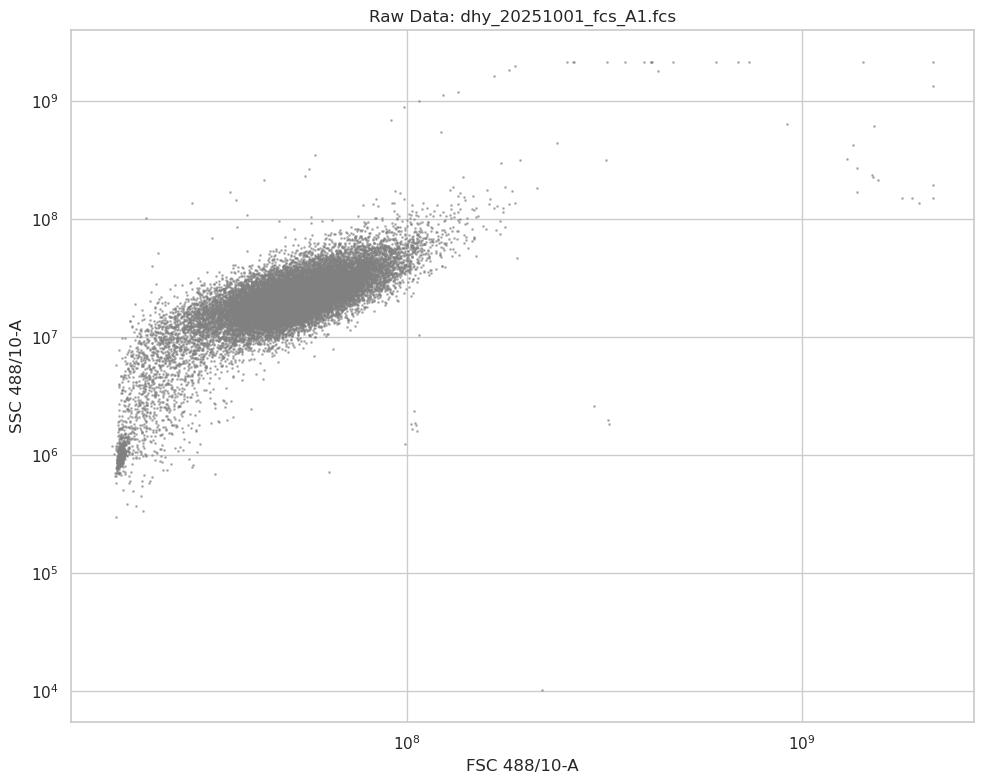

In [3]:
# 2. Visualize Raw Data (Scatter)
# Identify likely FSC/SSC channels
x_channel = "FSC 488/10-A" if "FSC 488/10-A" in experiment.channels else experiment.channels[0]
y_channel = "SSC 488/10-A" if "SSC 488/10-A" in experiment.channels else experiment.channels[1]

print(f"Plotting {x_channel} vs {y_channel}")

df = experiment.data
plt.figure(figsize=(10, 8))
plt.scatter(df[x_channel], df[y_channel], s=1, alpha=0.5, c='gray')
plt.xlabel(x_channel)
plt.ylabel(y_channel)
plt.title(f"Raw Data: {os.path.basename(target_file)}")
plt.semilogy()
plt.semilogx()
plt.show()

Applying Basic Density Gating (keep=0.9)...


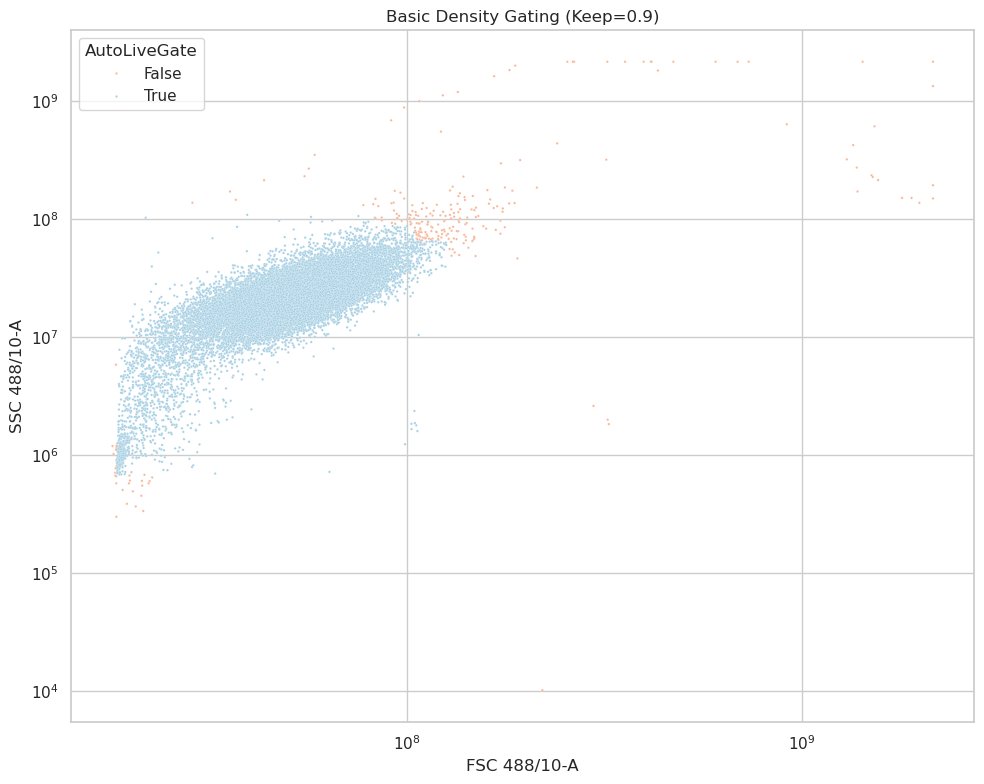

In [6]:
# 3. Test Basic Density Gating (No Outlier Removal)
gater = GatingManager()

keep_fraction = 0.9
print(f"Applying Basic Density Gating (keep={keep_fraction})...")

# Run Gating
gated_exp_density = gater.auto_gate_live_cells(experiment, 
                                               x_channel=x_channel, 
                                               y_channel=y_channel, 
                                               method='density', 
                                               keep=keep_fraction)

# Check results
df_density = gated_exp_density.data
gate_column = "AutoLiveGate" 

if gate_column in df_density.columns:
    # Visualization
    plt.figure(figsize=(10, 8))
    sns.scatterplot(data=df_density, x=x_channel, y=y_channel, hue=gate_column, s=3, palette='RdBu')
    plt.semilogy()
    plt.semilogx()
    plt.title(f"Basic Density Gating (Keep={keep_fraction})")
    plt.show()
else:
    print("Error: Gate column not found!")

Applying GMM Gating (2 Components)...


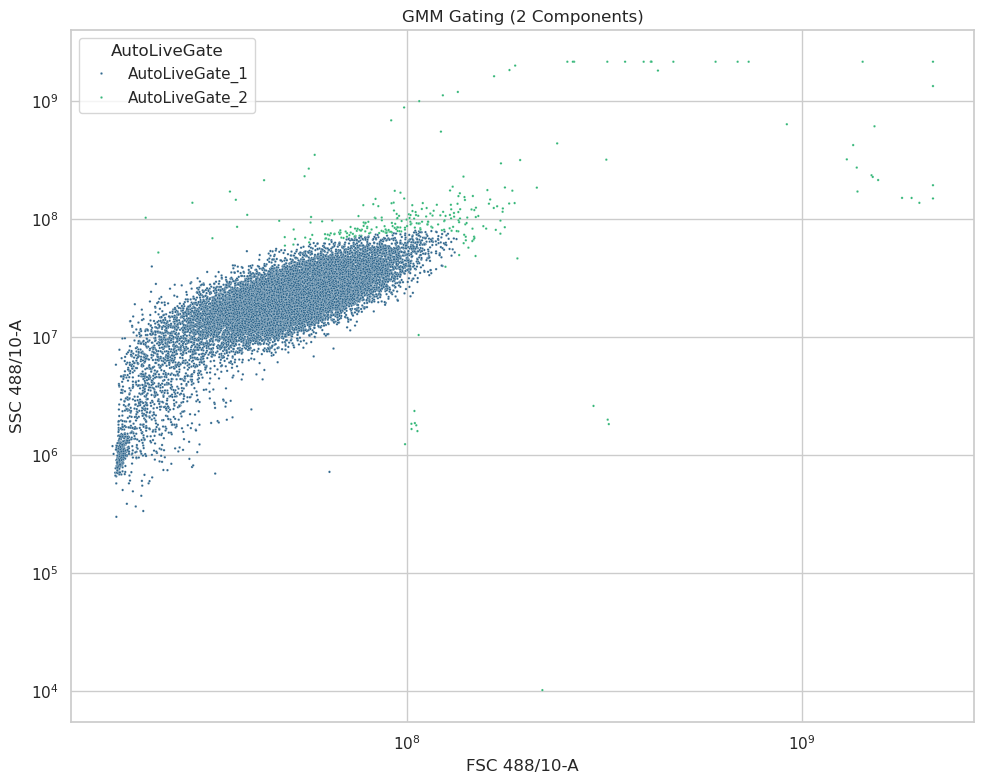

In [7]:
# 4. Test GMM Gating
print("Applying GMM Gating (2 Components)...")

try:
    gated_exp_gmm = gater.auto_gate_live_cells(experiment, 
                                               x_channel=x_channel, 
                                               y_channel=y_channel, 
                                               method='gmm', 
                                               num_components=2)

    df_gmm = gated_exp_gmm.data
    
    if gate_column in df_gmm.columns:
        plt.figure(figsize=(10, 8))
        sns.scatterplot(data=df_gmm, x=x_channel, y=y_channel, hue=gate_column, s=3, palette='viridis')
        plt.semilogy()
        plt.semilogx()
        plt.title("GMM Gating (2 Components)")
        plt.show()
    else:
        print("Error: Gate column not found!")
except Exception as e:
    print(f"GMM Gating Failed: {e}")

Applying Robust Density Gating (Isolation Forest + Density)...


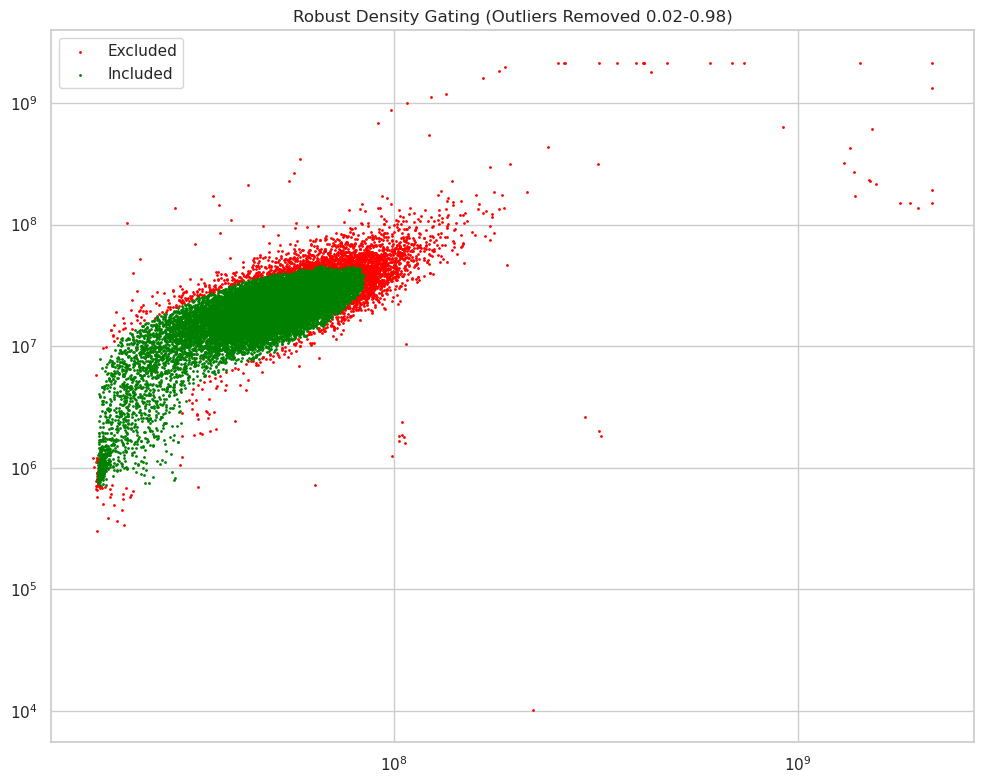

In [8]:
# 5. Test Robust Density Gating (With Outlier Removal)
# This uses the new parameters: method='density', use_outlier_removal=True
print("Applying Robust Density Gating (Isolation Forest + Density)...")

keep_fraction = 0.9
outlier_low = 0.02
outlier_high = 0.98

try:
    gated_exp_robust = gater.auto_gate_live_cells(experiment, 
                                                  x_channel=x_channel, 
                                                  y_channel=y_channel, 
                                                  method='density', 
                                                  keep=keep_fraction,
                                                  use_outlier_removal=True,
                                                  outlier_low=outlier_low,
                                                  outlier_high=outlier_high)

    df_robust = gated_exp_robust.data

    if gate_column in df_robust.columns:
        kept_mask = df_robust[gate_column].astype(bool) if df_robust[gate_column].dtype == bool else (df_robust[gate_column].astype(str) == 'True')
        
        plt.figure(figsize=(10, 8))
        # Plot Excluded
        plt.scatter(df_robust.loc[~kept_mask, x_channel], df_robust.loc[~kept_mask, y_channel], 
                    c='red', s=1, label='Excluded')
        # Plot Included
        plt.scatter(df_robust.loc[kept_mask, x_channel], df_robust.loc[kept_mask, y_channel], 
                    c='green', s=1, label='Included')
        
        plt.semilogy()
        plt.semilogx()
        plt.legend()
        plt.title(f"Robust Density Gating (Outliers Removed {outlier_low}-{outlier_high})")
        plt.show()
    else:
        print("Error: Gate column not found!")
        
except Exception as e:
    print(f"An error occurred: {e}")
    import traceback
    traceback.print_exc()

# 6. Test Isolation Forest (Outlier Detection Visualization)
This section specifically tests the outlier detection component of the Smart Gating strategy using `IsolationForest`.
We visualize which events are classified as "inliers" (clean data) vs "outliers" (debris/aggregates) before any density gating is applied.

Testing OutlierDetector Class independently...
Original Event Count: 19184
Clean Subset Event Count: 18800
Outliers Removed: 384


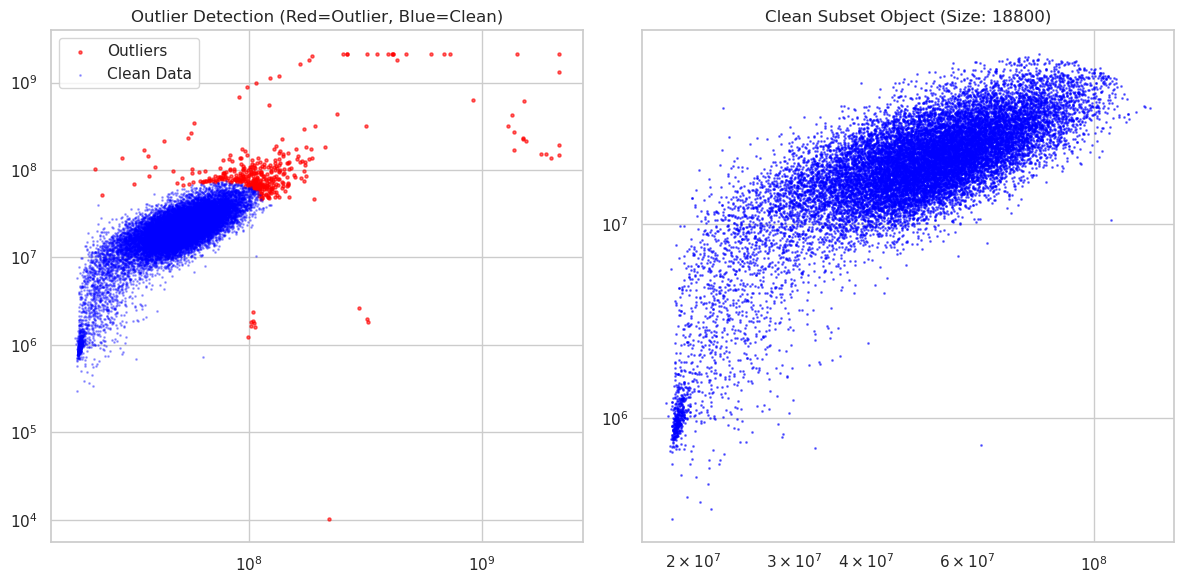

In [4]:
# 6. Unit Test: OutlierDetector Class
# Specifically verify the clean subset generation with visual confirmation of what was removed
print("Testing OutlierDetector Class independently...")

detector = OutlierDetector(method='isolation_forest', outlier_low=0.01, outlier_high=0.99)

print(f"Original Event Count: {len(experiment.data)}")

try:
    # 1. Get the Mask directly (New Feature)
    mask = detector.get_mask(experiment, channels=[x_channel, y_channel])
    
    # 2. Get the clean experiment (Standard Usage)
    clean_exp = detector.get_clean_subset(experiment, channels=[x_channel, y_channel])
    
    print(f"Clean Subset Event Count: {len(clean_exp.data)}")
    print(f"Outliers Removed: {(~mask).sum()}")
    
    # Visualize Original vs Clean+Outliers
    plt.figure(figsize=(12, 6))
    
    # Plot 1: Standard Side-by-Side
    plt.subplot(1, 2, 1)
    # Plot Outliers first
    plt.scatter(experiment.data.loc[~mask, x_channel], experiment.data.loc[~mask, y_channel], 
                c='red', s=5, alpha=0.6, label='Outliers')
    # Plot Inliers
    plt.scatter(experiment.data.loc[mask, x_channel], experiment.data.loc[mask, y_channel], 
                c='blue', s=1, alpha=0.3, label='Clean Data')
    
    plt.semilogy(); plt.semilogx()
    plt.legend()
    plt.title(f"Outlier Detection (Red=Outlier, Blue=Clean)")
    
    # Plot 2: Just the Clean Subset (Verification of object creation)
    plt.subplot(1, 2, 2)
    plt.scatter(clean_exp.data[x_channel], clean_exp.data[y_channel], c='blue', s=1, alpha=0.5)
    plt.semilogy(); plt.semilogx()
    plt.title(f"Clean Subset Object (Size: {len(clean_exp.data)})")
    
    plt.show()

except Exception as e:
    print(f"OutlierDetector Test Failed: {e}")
    import traceback
    traceback.print_exc()